# Demo: un asistente de códigos de error que aprende sin reentrenarse

- Santiago Betancur
- Santiago Vélez



In [ ]:
%pip install -q "psycopg[binary]" pgvector umap-learn sentence-transformers

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.2/5.2 MB 13.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 215.5/215.5 kB 16.1 MB/s eta 0:00:00


In [ ]:
import os
import re
import time
import unicodedata
import warnings
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import psycopg
from pgvector.psycopg import register_vector
from sentence_transformers import SentenceTransformer

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 120)

SEMILLA = 50
MODELO = "intfloat/multilingual-e5-small"
TABLA = "codigos_velora"
K = 5
NUEVA_CATEGORIA = "Moto eléctrica E-Volt"
np.random.seed(SEMILLA)

CATEGORIAS = ["Motor e inyección", "Sistema eléctrico", "Frenos y suspensión",
              "Transmisión y cadena", "Refrigeración y lubricación", NUEVA_CATEGORIA]
COLORES = dict(zip(CATEGORIAS, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]))
MARCADORES = dict(zip(CATEGORIAS, ["o", "s", "^", "D", "v", "P"]))
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})

try:
    from google.colab import userdata
    DB_URL = userdata.get("SUPABASE_DB_URL")
except ImportError:
    DB_URL = os.environ["SUPABASE_DB_URL"]

modelo = SentenceTransformer(MODELO)
DIM = modelo.get_sentence_embedding_dimension()


def embeber(textos):
    return modelo.encode(["query: " + t for t in textos], normalize_embeddings=True,
                         batch_size=32, show_progress_bar=False)


def armar_texto(codigo, categoria, falla, sintoma, solucion):
    return f"Código {codigo}. Sistema: {categoria}. Falla: {falla}. Síntoma: {sintoma}. Solución: {solucion}"


print(f"Modelo cargado: {MODELO} ({DIM} dimensiones)")

modules.json:   0%|          | 0.00/387 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/498k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/57.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/655 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  471MB            

...

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.1MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/167 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/200 [00:00<?, ?B/s]

Modelo cargado: intfloat/multilingual-e5-small (384 dimensiones)


In [ ]:
PRUEBA = [
    ["Me aparece el código E-03 en el tablero", "E-03", "código"],
    ["¿Qué significa C-11?", "C-11", "código"],
    ["La moto marca F-06", "F-06", "código"],
    ["Salió T-05, ¿es grave?", "T-05", "código"],
    ["En la pantalla dice L-11", "L-11", "código"],
    ["¿Qué hago con un C-23?", "C-23", "código"],
    ["La Trail tiene el F-01", "F-01", "código"],
    ["Me sale T-17", "T-17", "código"],
    ["Código L-06 en el tablero", "L-06", "código"],
    ["¿Qué es el E-16?", "E-16", "código"],
    ["La moto se me apaga cuando paro en un semáforo", "E-03", "síntoma"],
    ["Se me cayó la moto y ahora no quiere prender", "C-13", "síntoma"],
    ["El velocímetro se quedó en cero aunque voy andando", "C-12", "síntoma"],
    ["Las direccionales titilan muy rápido", "C-09", "síntoma"],
    ["La batería amanece descargada todos los días", "C-24", "síntoma"],
    ["Cuando freno suena un chillido metálico", "F-07", "síntoma"],
    ["El freno de adelante se siente blandito", "F-06", "síntoma"],
    ["La moto vibra cuando freno duro", "F-09", "síntoma"],
    ["Suena la cadena cuando acelero", "T-03", "síntoma"],
    ["El clutch patina cuando subo una loma", "T-06", "síntoma"],
    ["Sale humo azulado por el exosto", "L-14", "síntoma"],
    ["El aceite se ve como café con leche", "L-19", "síntoma"],
    ["Se recalienta cuando estoy en un trancón", "L-03", "síntoma"],
    ["Huele mucho a gasolina con la moto parada", "E-22", "síntoma"],
    ["Se me hunde la moto cuando llevo parrillero", "F-15", "síntoma"],
    ["Pierde fuerza cuando subo a la montaña", "E-21", "síntoma"],
    ["Tengo el E-09 y el motor gira pero no prende", "E-09", "mixta"],
    ["Salió el L-01 y la aguja de temperatura está en rojo", "L-01", "mixta"],
    ["Me sale C-05 y solo suena un clic", "C-05", "mixta"],
    ["La moto marca T-01 y no prende la luz del neutro", "T-01", "mixta"],
    ["Apareció F-04 y la manigueta se va hasta el fondo", "F-04", "mixta"],
]

In [ ]:
conn = psycopg.connect(DB_URL, autocommit=True)
conn.execute("create extension if not exists vector")
register_vector(conn)
version = conn.execute("select extversion from pg_extension where extname = 'vector'").fetchone()[0]
print(f"Conectados a Supabase. pgvector activo, versión {version}")


def insertar_codigos(filas):
    textos = [armar_texto(*f) for f in filas]
    vectores = embeber(textos)
    with conn.cursor() as cur:
        cur.executemany(
            f"insert into {TABLA} (codigo, categoria, falla, sintoma, solucion, texto, embedding) "
            "values (%s, %s, %s, %s, %s, %s, %s)",
            [(*f, t, v) for f, t, v in zip(filas, textos, vectores)])
    return len(filas)


STOPWORDS = set("a al como con cual cuando de del el en es esta este hay la las le lo los me mi muy "
                "o para pero por que se si sin su un una y ya yo".split())
STOPWORDS |= set("codigo aparece aparecio sale salio marca dice tablero pantalla significa tiene tengo hago grave moto".split())

def tokens_bm25(texto):
    t = unicodedata.normalize("NFKD", texto.lower()).encode("ascii", "ignore").decode()
    return [w for w in re.findall(r"[a-z]-\d+|[a-z0-9]+", t) if w not in STOPWORDS]


class BM25:
    def __init__(self, textos, k1=1.5, b=0.75):
        self.docs = [Counter(tokens_bm25(t)) for t in textos]
        self.largos = np.array([sum(d.values()) for d in self.docs])
        self.prom = self.largos.mean()
        self.k1, self.b, n = k1, b, len(textos)
        df = Counter(w for d in self.docs for w in d)
        self.idf = {w: np.log(1 + (n - c + 0.5) / (c + 0.5)) for w, c in df.items()}

    def puntajes(self, consulta):
        q = tokens_bm25(consulta)
        s = np.zeros(len(self.docs))
        for i, (d, largo) in enumerate(zip(self.docs, self.largos)):
            for w in q:
                if w in d:
                    f = d[w]
                    s[i] += self.idf[w] * f * (self.k1 + 1) / (f + self.k1 * (1 - self.b + self.b * largo / self.prom))
        return s


COLUMNAS = ["id", "codigo", "categoria", "falla", "sintoma", "solucion", "texto"]


def cargar_catalogo():
    filas = conn.execute(f"select {', '.join(COLUMNAS)}, embedding from {TABLA} order by id").fetchall()
    tabla = pd.DataFrame([f[:-1] for f in filas], columns=COLUMNAS)
    E = np.vstack([np.asarray(f[-1].to_numpy() if hasattr(f[-1], "to_numpy") else f[-1], dtype=float) for f in filas])
    return tabla, E


def actualizar_indices():
    global catalogo, E_catalogo, bm25
    catalogo, E_catalogo = cargar_catalogo()
    bm25 = BM25(catalogo["texto"].tolist())


SQL_DENSE = f'''
    select id, 1 - (embedding <=> %(q)s) as similitud
    from {TABLA}
    order by embedding <=> %(q)s
    limit %(n)s
'''


def buscar(pregunta, metodo="hybrid", n=10, vector=None):
    if metodo == "sparse":
        s = bm25.puntajes(pregunta)
        orden = np.argsort(-s)[:n]
        res = catalogo.iloc[orden].assign(puntaje=s[orden])
    elif metodo == "dense":
        v = embeber([pregunta])[0] if vector is None else vector
        filas = conn.execute(SQL_DENSE, {"q": v, "n": n}).fetchall()
        res = catalogo.set_index("id").loc[[f[0] for f in filas]].reset_index().assign(puntaje=[f[1] for f in filas])
    elif metodo == "hybrid":
        sparse = buscar(pregunta, "sparse", 20)
        sparse = sparse[sparse["puntaje"] > 0]
        rrf = {}
        for lista in (sparse, buscar(pregunta, "dense", 20, vector)):
            for pos, i in enumerate(lista["id"], start=1):
                rrf[i] = rrf.get(i, 0) + 1 / (60 + pos)
        ids = sorted(rrf, key=rrf.get, reverse=True)[:n]
        res = catalogo.set_index("id").loc[ids].reset_index().assign(puntaje=[rrf[i] for i in ids])
    else:
        raise ValueError("metodo debe ser 'sparse', 'dense' o 'hybrid'")
    return res.reset_index(drop=True)


def categoria_votada(resultados, k=K):
    top = list(resultados.head(k)["categoria"])
    return max(top, key=lambda c: (top.count(c), -top.index(c)))


def evaluar(metodo, preguntas):
    filas = []
    for texto, codigo, tipo in preguntas:
        res = buscar(texto, metodo, n=10)
        codigos = list(res["codigo"])
        rango = codigos.index(codigo) + 1 if codigo in codigos else None
        filas.append({"pregunta": texto, "tipo": tipo, "correcto": codigo, "recuperado": codigos[0],
                      "acierto@1": rango == 1, "acierto@3": rango is not None and rango <= 3,
                      "MRR": 1 / rango if rango else 0.0,
                      "categoría correcta": categoria_votada(res) == CATEGORIA_DE[codigo]})
    return pd.DataFrame(filas)


def consultar(sql, params=None):
    cur = conn.execute(sql, params)
    return pd.DataFrame(cur.fetchall(), columns=[c.name for c in cur.description])


conn.execute(f"delete from {TABLA} where categoria = %s", (NUEVA_CATEGORIA,))
actualizar_indices()
catalogo_inicial, E_inicial = catalogo.copy(), E_catalogo.copy()
CATEGORIA_DE = dict(zip(catalogo["codigo"], catalogo["categoria"]))

sims_normales = [float(conn.execute(SQL_DENSE, {"q": v, "n": 1}).fetchone()[1]) for v in embeber([p for p, _, _ in PRUEBA])]
UMBRAL = float(np.percentile(sims_normales, 5)) - 0.01
METODO = "hybrid"


def responder(pregunta, metodo=METODO):
    v = embeber([pregunta])[0]
    sim_max = float(conn.execute(SQL_DENSE, {"q": v, "n": 1}).fetchone()[1])
    res = buscar(pregunta, metodo, n=K, vector=v)
    print(f"Pregunta: {pregunta}   (método: {metodo})\n")
    if sim_max < UMBRAL:
        print(f"No encontré información sobre eso en el catálogo "
              f"(similitud máxima {sim_max:.3f}, menor que el umbral {UMBRAL:.3f}).")
    else:
        top = res.loc[0]
        print(f"Código:    {top['codigo']}")
        print(f"Falla:     {top['falla']}")
        print(f"Solución:  {top['solucion']}")
        print(f"Categoría (votada por {K} vecinos): {categoria_votada(res)}")
    return res[["codigo", "categoria", "falla", "solucion", "puntaje"]].round(3)


print(f"Base lista: {len(catalogo)} códigos en el catálogo. Umbral de similitud: {UMBRAL:.3f}")

Conectados a Supabase. pgvector activo, versión 0.8.2
Base lista: 120 códigos en el catálogo. Umbral de similitud: 0.828


## 1. ¿Qué sabe el sistema hoy?

Todo lo que el asistente sabe está en la tabla `codigos_velora`. Cada fila es un código con su categoría, su falla, su síntoma, su solución y su embedding.

In [ ]:
consultar(f"select categoria, count(*) as codigos from {TABLA} group by categoria order by categoria")

,categoria,codigos
0,Frenos y suspensión,24
1,Motor e inyección,24
2,Refrigeración y lubricación,24
3,Sistema eléctrico,24
4,Transmisión y cadena,24


In [ ]:
consultar(f"select codigo, categoria, falla, sintoma, solucion from {TABLA} where codigo in ('E-03', 'C-13', 'F-07', 'T-03', 'L-11')")

,codigo,categoria,falla,sintoma,solucion
0,E-03,Motor e inyección,Inyector de combustible obstruido,la moto se apaga en ralentí y tironea al acelerar,Limpie el inyector por ultrasonido; reemplácelo si el patrón de rociado es irregular.
1,C-13,Sistema eléctrico,Sensor de caída activado,el motor no enciende después de una caída o volcamiento,"Levante la moto, apague la llave, espere 10 segundos y vuelva a encender."
2,F-07,Frenos y suspensión,Pastillas delanteras gastadas,chillido metálico al frenar,Cambie las pastillas delanteras.
3,T-03,Transmisión y cadena,Cadena destensionada,la cadena suena o golpea al acelerar,Ajuste la holgura de la cadena a 25 - 35 mm.
4,L-11,Refrigeración y lubricación,Presión de aceite baja,la luz de aceite está encendida,Apague el motor de inmediato y revise el nivel de aceite.


## 2. Cómo una pregunta se vuelve un vector

**Tokenización.**

In [ ]:
pregunta = "Me sale E-03 en el tablero"
ids = modelo.tokenizer("query: " + pregunta)["input_ids"]
pd.DataFrame([modelo.tokenizer.convert_ids_to_tokens(ids), ids], index=["token", "id"])

,0,1,2,3,4,5,6,7,8,9,10,11,12
token,<s>,▁que,ry,:,▁Me,▁sale,▁E,-03,▁en,▁el,▁table,ro,</s>
id,0,41,1294,12,1215,11473,241,97540,22,88,23180,516,2


**Embedding.**

In [ ]:
v = embeber([pregunta])[0]
print(f"Dimensión: {v.shape[0]}")
print(f"Primeros 10 valores: {np.round(v[:10], 3)}")
print(f"Norma: {np.linalg.norm(v):.4f}")

Dimensión: 384
Primeros 10 valores: [ 0.06   0.002 -0.028 -0.037  0.092 -0.016 -0.006  0.019  0.041  0.007]
Norma: 1.0000


**Similitud.**

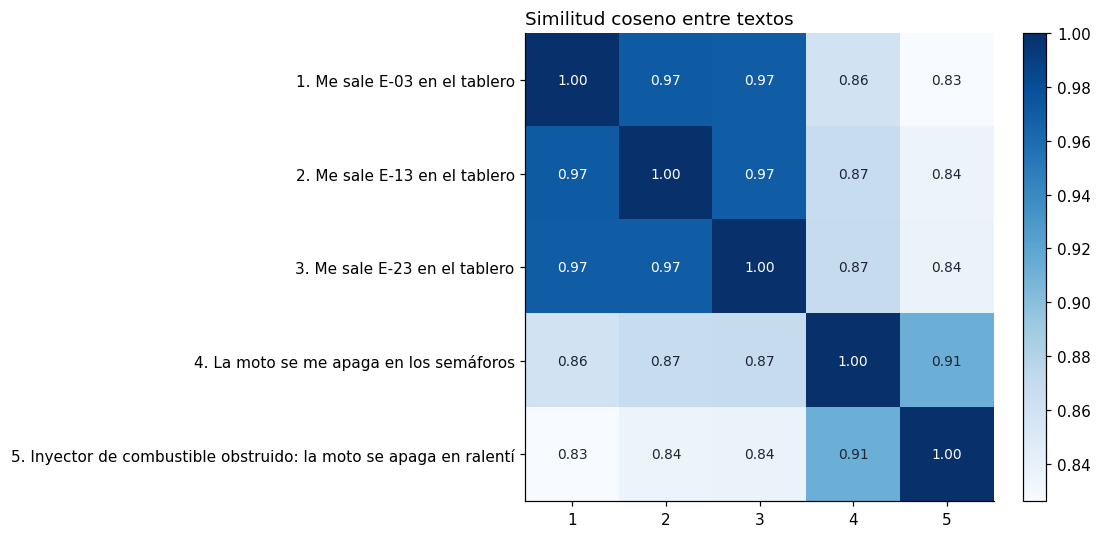

E-03 vs E-13 (solo cambia el número):  0.971
Síntoma vs catálogo (otras palabras):  0.912


In [ ]:
frases = [
    "Me sale E-03 en el tablero",
    "Me sale E-13 en el tablero",
    "Me sale E-23 en el tablero",
    "La moto se me apaga en los semáforos",
    "Inyector de combustible obstruido: la moto se apaga en ralentí",
]
Ef = embeber(frases)
S = Ef @ Ef.T
fig, ax = plt.subplots(figsize=(8.5, 5))
im = ax.imshow(S, cmap="Blues", vmin=S.min(), vmax=1)
for i in range(len(frases)):
    for j in range(len(frases)):
        ax.text(j, i, f"{S[i, j]:.2f}", ha="center", va="center", fontsize=9,
                color="white" if S[i, j] > (S.min() + 1) / 2 else "#1d2633")
ax.set_yticks(range(len(frases)), [f"{i + 1}. {f}" for i, f in enumerate(frases)])
ax.set_xticks(range(len(frases)), [str(i + 1) for i in range(len(frases))])
ax.set_title("Similitud coseno entre textos", loc="left")
fig.colorbar(im, ax=ax, fraction=0.04)
plt.tight_layout()
plt.show()
print(f"E-03 vs E-13 (solo cambia el número):  {S[0, 1]:.3f}")
print(f"Síntoma vs catálogo (otras palabras):  {S[3, 4]:.3f}")

Un buscador por palabras ve "e-03" y "e-13" como palabras distintas, así que no las confunde. Para el embedding, en cambio, pueden quedar casi iguales. Por eso en la sección 5 comparamos los dos tipos de búsqueda.

## 3. Un mapa del catálogo

Proyectamos a 2D los 384 números de cada uno de los 120 códigos, leídos desde Supabase y coloreados por categoría. En UMAP lo que cuenta es quién queda cerca de quién: las distancias entre grupos y su tamaño no significan nada.

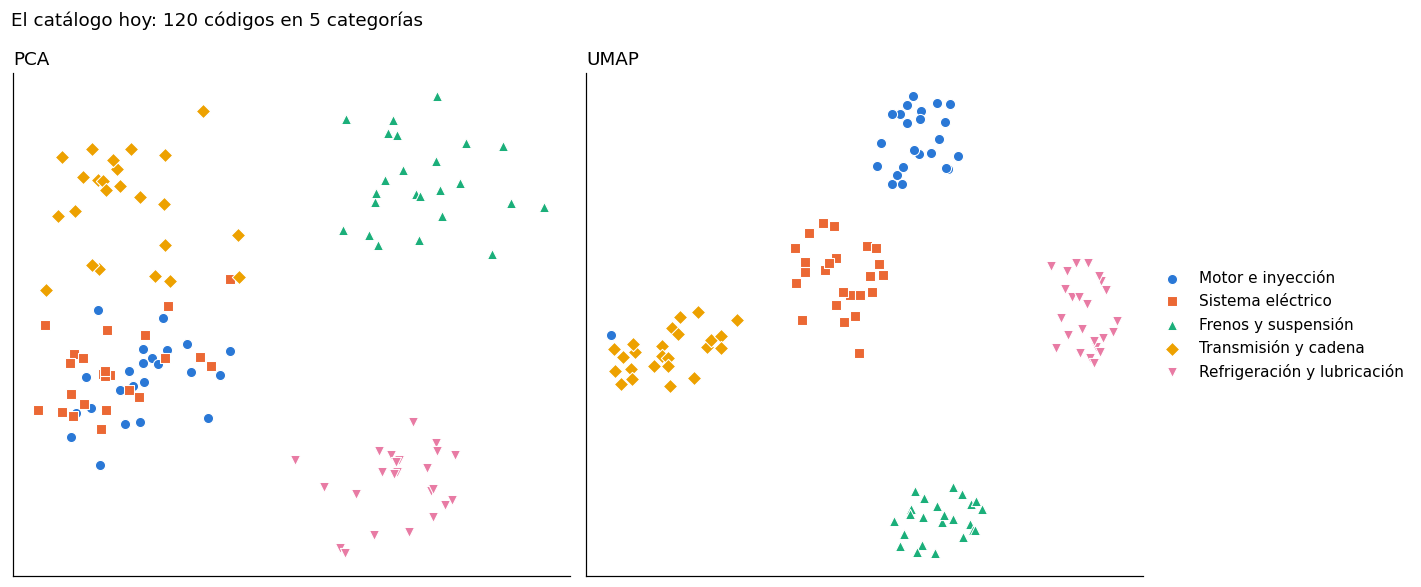

In [ ]:
import umap
from sklearn.decomposition import PCA


def dibujar_mapa(tabla, E, titulo):
    Z_pca = PCA(n_components=2, random_state=SEMILLA).fit_transform(E)
    Z_umap = umap.UMAP(n_neighbors=15, min_dist=0.1, metric="cosine", random_state=SEMILLA).fit_transform(E)
    fig, axes = plt.subplots(1, 2, figsize=(13, 5.4))
    for ax, Z, nombre in [(axes[0], Z_pca, "PCA"), (axes[1], Z_umap, "UMAP")]:
        for cat in CATEGORIAS:
            m = (tabla["categoria"] == cat).to_numpy()
            if m.any():
                ax.scatter(Z[m, 0], Z[m, 1], s=44, c=COLORES[cat], marker=MARCADORES[cat],
                           edgecolor="white", linewidth=0.7, label=cat)
        ax.set_title(nombre, loc="left")
        ax.set_xticks([])
        ax.set_yticks([])
    axes[1].legend(loc="center left", bbox_to_anchor=(1.0, 0.5), frameon=False)
    fig.suptitle(titulo, x=0.01, ha="left")
    plt.tight_layout()
    plt.show()


dibujar_mapa(catalogo_inicial, E_inicial, f"El catálogo hoy: {len(catalogo_inicial)} códigos en 5 categorías")

## 4. Preguntarle al catálogo

Para cada pregunta, el sistema:

1. recupera los códigos más relevantes; aquí usamos **hybrid**, que combina palabras y significado;
2. muestra el primero como **respuesta**, con su falla y su solución;
3. hace que los 5 primeros **voten por la categoría** (k-NN);
4. si nada se parece lo suficiente, responde **"no encontré información"**.

La tabla de abajo es la **evidencia**: los códigos en los que se basó la respuesta.

In [ ]:
responder("La luz de stop no se prende cuando presiono el freno")

Pregunta: La luz de stop no se prende cuando presiono el freno   (método: hybrid)

Código:    C-18
Falla:     Luz de freno no enciende
Solución:  Revise el bombillo y los interruptores de freno.
Categoría (votada por 5 vecinos): Sistema eléctrico


,codigo,categoria,falla,solucion,puntaje
0,C-18,Sistema eléctrico,Luz de freno no enciende,Revise el bombillo y los interruptores de freno.,0.033
1,C-17,Sistema eléctrico,Luz de freno siempre encendida,Ajuste el interruptor del freno trasero.,0.033
2,C-07,Sistema eléctrico,Fusible principal fundido,Busque el cortocircuito antes de cambiar el fusible principal de 15 A.,0.031
3,T-01,Transmisión y cadena,Sensor de neutro con falla,Revise el sensor de neutro ubicado sobre la caja de cambios.,0.030
4,L-11,Refrigeración y lubricación,Presión de aceite baja,Apague el motor de inmediato y revise el nivel de aceite.,0.030


In [ ]:
responder("Me salió el codigo L-11 en el tablero de mi moto, ¿qué hago?")

Pregunta: Me salió el codigo L-11 en el tablero de mi moto, ¿qué hago?   (método: hybrid)

Código:    L-11
Falla:     Presión de aceite baja
Solución:  Apague el motor de inmediato y revise el nivel de aceite.
Categoría (votada por 5 vecinos): Refrigeración y lubricación


,codigo,categoria,falla,solucion,puntaje
0,L-11,Refrigeración y lubricación,Presión de aceite baja,Apague el motor de inmediato y revise el nivel de aceite.,0.032
1,C-11,Sistema eléctrico,El inmovilizador no reconoce la llave,Pruebe con la llave de repuesto y reprograme la llave principal en el taller.,0.016
2,C-13,Sistema eléctrico,Sensor de caída activado,"Levante la moto, apague la llave, espere 10 segundos y vuelva a encender.",0.016
3,L-03,Refrigeración y lubricación,El ventilador no enciende,Revise el fusible y el relé del ventilador.,0.016
4,T-11,Transmisión y cadena,Pedal de cambios flojo,Apriete el tornillo del pedal de cambios.,0.016


## 5. Comparar los métodos: sparse, dense e hybrid

- **Sparse (BM25):** busca por **palabras**. Es fuerte con términos exactos, como los códigos.
- **Dense (embeddings en pgvector):** busca por **significado**. Es fuerte cuando la pregunta usa otras palabras.
- **Hybrid (RRF):** **fusiona los dos rankings** con Reciprocal Rank Fusion.

Primero, cuatro preguntas de ejemplo. Cada celda muestra el código que quedó en primer lugar.

In [ ]:
ejemplos = [
    ("Me aparece el código E-03 en el tablero", "E-03"),
    ("La moto se mueve aunque esté presionando el clutch", "T-07"),
    ("Se me cayó la moto y ahora no quiere prender", "C-13"),
    ("Salió el L-01 y la aguja de temperatura está en rojo", "L-01"),
]
tabla = pd.DataFrame({"correcto": [c for _, c in ejemplos]}, index=[p for p, _ in ejemplos])
for m in ["sparse", "dense", "hybrid"]:
    primeros = [buscar(p, m, n=1).loc[0, "codigo"] for p, _ in ejemplos]
    tabla[m] = [f"{r} (bien)" if r == c else f"{r} (mal)" for r, (_, c) in zip(primeros, ejemplos)]
tabla

,correcto,sparse,dense,hybrid
Me aparece el código E-03 en el tablero,E-03,E-03 (bien),E-03 (bien),E-03 (bien)
La moto se mueve aunque esté presionando el clutch,T-07,T-07 (bien),T-07 (bien),T-07 (bien)
Se me cayó la moto y ahora no quiere prender,C-13,E-06 (mal),C-13 (bien),C-11 (mal)
Salió el L-01 y la aguja de temperatura está en rojo,L-01,L-01 (bien),L-01 (bien),L-01 (bien)


Ahora con las 31 preguntas de prueba:

In [ ]:
resultados = {m: evaluar(m, PRUEBA) for m in ["sparse", "dense", "hybrid"]}
resumen = pd.DataFrame({m: r[["acierto@1", "acierto@3", "categoría correcta"]].mean()
                        for m, r in resultados.items()}).T
resumen.round(3)

,acierto@1,acierto@3,categoría correcta
sparse,0.871,0.935,0.548
dense,0.839,0.968,0.806
hybrid,0.903,0.968,0.871


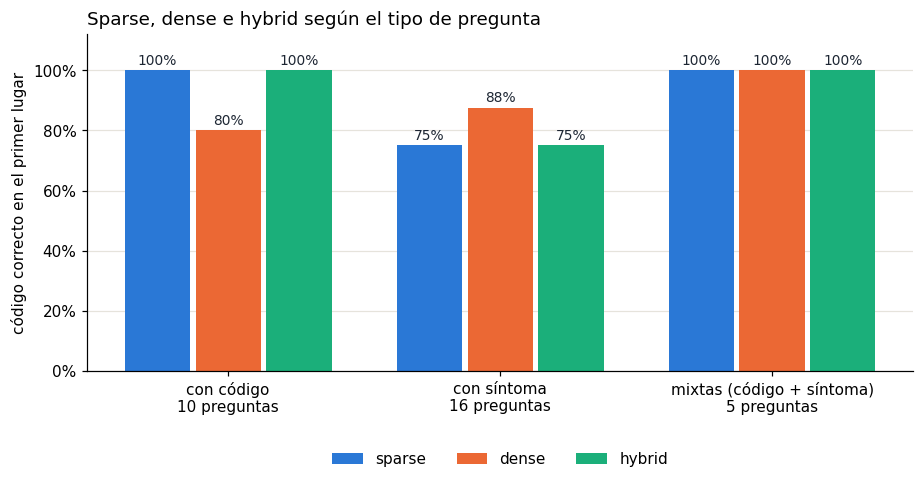

In [ ]:
por_tipo = pd.DataFrame({m: r.groupby("tipo")["acierto@1"].mean() for m, r in resultados.items()}).T
por_tipo = por_tipo[[c for c in ["código", "síntoma", "mixta"] if c in por_tipo.columns]]

fig, ax = plt.subplots(figsize=(8.5, 4.6))
ancho = 0.26
colores_metodo = {"sparse": "#2a78d6", "dense": "#eb6834", "hybrid": "#1baf7a"}
x = np.arange(len(por_tipo.columns))
for j, metodo in enumerate(por_tipo.index):
    valores = por_tipo.loc[metodo].to_numpy()
    barras = ax.bar(x + (j - 1) * ancho, valores, width=ancho - 0.02, color=colores_metodo[metodo], label=metodo)
    for b, v in zip(barras, valores):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.02, f"{v:.0%}", ha="center", fontsize=9, color="#1d2633")
n_por_tipo = resultados["dense"]["tipo"].value_counts()
nombres = {"código": "con código", "síntoma": "con síntoma", "mixta": "mixtas (código + síntoma)"}
ax.set_xticks(x, [f"{nombres[t]}\n{n_por_tipo[t]} preguntas" for t in por_tipo.columns])
ax.set_ylim(0, 1.12)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_ylabel("código correcto en el primer lugar")
ax.set_title("Sparse, dense e hybrid según el tipo de pregunta", loc="left")
ax.legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.2))
ax.grid(axis="y", color="#e6e3dc", linewidth=0.8)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

## 6. Llega la E-Volt: códigos que el sistema no conoce

Velora lanza su primera moto eléctrica. Trae códigos nuevos que todavía no están en la base de datos.

In [ ]:
pregunta_nueva = "Mi E-Volt muestra B-02 y el cargador no inicia la carga"
evidencia = responder(pregunta_nueva)
if evidencia.loc[0, "codigo"] != "B-02":
    print("\n-> El código B-02 no existe en la base: el sistema no puede dar la respuesta correcta.")
evidencia

Pregunta: Mi E-Volt muestra B-02 y el cargador no inicia la carga   (método: hybrid)

Código:    C-01
Falla:     Voltaje de batería bajo
Solución:  Cargue la batería con cargador lento; cámbiela si no retiene la carga.
Categoría (votada por 5 vecinos): Sistema eléctrico

-> El código B-02 no existe en la base: el sistema no puede dar la respuesta correcta.


,codigo,categoria,falla,solucion,puntaje
0,C-01,Sistema eléctrico,Voltaje de batería bajo,Cargue la batería con cargador lento; cámbiela si no retiene la carga.,0.033
1,C-02,Sistema eléctrico,Sobrevoltaje en el sistema de carga,"Revise el regulador; el voltaje de carga debe estar entre 13,5 y 14,5 V.",0.032
2,C-04,Sistema eléctrico,Estator con bobinas quemadas,Mida la resistencia del estator y reemplácelo.,0.031
3,C-20,Sistema eléctrico,Puerto USB sin corriente,Revise el fusible del puerto USB.,0.031
4,C-03,Sistema eléctrico,Regulador rectificador defectuoso,Mida el voltaje de carga en marcha y cambie el regulador.,0.031


Puede pasar una de dos cosas: que el sistema diga que **no encontró información**, o que devuelva un código **parecido pero equivocado**, por ejemplo uno de batería de las motos de gasolina. Lo segundo es justo el riesgo de un sistema que responde sin tener la información.

Lo mismo pasa con otras preguntas sobre la E-Volt:

In [ ]:
PRUEBA_EVOLT = [
    ["Mi E-Volt muestra B-02 y el cargador no inicia la carga", "B-02", "mixta"],
    ["¿Qué significa B-06 en la E-Volt?", "B-06", "código"],
    ["La moto eléctrica dejó de cargar y la batería está muy caliente", "B-04", "síntoma"],
    ["Cada vez me rinde menos la carga de la E-Volt", "B-05", "síntoma"],
    ["Lavé la E-Volt y ahora no me deja cargar", "B-07", "síntoma"],
    ["La E-Volt se puso lenta de repente y no pasa de 30", "M-01", "síntoma"],
    ["La eléctrica prende pero no avanza", "M-02", "síntoma"],
    ["La E-Volt ya no recupera carga cuando freno", "M-04", "síntoma"],
]

CATEGORIA_DE.update({c: NUEVA_CATEGORIA for _, c, _ in PRUEBA_EVOLT})
antes = evaluar(METODO, PRUEBA_EVOLT)
print(f"Respuestas correctas antes de subir los códigos nuevos: {antes['acierto@1'].mean():.0%}")
antes[["pregunta", "correcto", "recuperado"]]

Respuestas correctas antes de subir los códigos nuevos: 0%


,pregunta,correcto,recuperado
0,Mi E-Volt muestra B-02 y el cargador no inicia la carga,B-02,C-01
1,¿Qué significa B-06 en la E-Volt?,B-06,E-21
2,La moto eléctrica dejó de cargar y la batería está muy caliente,B-04,C-01
3,Cada vez me rinde menos la carga de la E-Volt,B-05,C-03
4,Lavé la E-Volt y ahora no me deja cargar,B-07,C-01
5,La E-Volt se puso lenta de repente y no pasa de 30,M-01,E-06
6,La eléctrica prende pero no avanza,M-02,C-18
7,La E-Volt ya no recupera carga cuando freno,M-04,C-01


## 7. Subimos los códigos de la E-Volt

Estos son los 12 códigos nuevos, cada uno con su falla, su síntoma y su solución. Los convertimos en vectores y los guardamos en Supabase con un `INSERT`. **No se entrena ni se ajusta ningún modelo.**

In [ ]:
CODIGOS_EVOLT = [
    ["B-01", "Moto eléctrica E-Volt", "Batería de tracción descargada", "la moto no avanza y el tablero muestra 0 %", "Cargue la batería completa; tarda unas 6 horas en un tomacorriente normal."],
    ["B-02", "Moto eléctrica E-Volt", "El cargador no se comunica con la batería", "el cargador no inicia la carga", "Revise que el conector esté bien insertado, use el cargador original y reconecte después de 30 segundos."],
    ["B-03", "Moto eléctrica E-Volt", "Batería demasiado fría", "la carga se demora mucho en clima frío", "Cargue la moto en un lugar a más de 10 °C."],
    ["B-04", "Moto eléctrica E-Volt", "Temperatura de la batería alta", "la carga se pausa sola", "Deje la moto a la sombra 30 minutos; la carga se reanuda sola."],
    ["B-05", "Moto eléctrica E-Volt", "Desbalance entre celdas de la batería", "la autonomía baja poco a poco", "Lleve la moto al taller para balancear las celdas."],
    ["B-06", "Moto eléctrica E-Volt", "Falla de aislamiento del alto voltaje", "aparece un aviso rojo en el tablero", "No toque los cables naranja ni use la moto; llévela al taller en grúa."],
    ["B-07", "Moto eléctrica E-Volt", "Conector de carga mojado", "no deja cargar después de lavar la moto", "Seque bien el conector de carga antes de conectar el cargador."],
    ["B-08", "Moto eléctrica E-Volt", "Sobrecorriente en la descarga", "se corta la potencia al acelerar a fondo", "Acelere de forma progresiva y haga revisar el sistema de gestión de la batería."],
    ["M-01", "Moto eléctrica E-Volt", "Motor eléctrico sobrecalentado", "la moto se limita a 30 km/h en modo tortuga", "Detenga la moto unos minutos para que el motor se enfríe."],
    ["M-02", "Moto eléctrica E-Volt", "Falla del controlador del motor", "la moto prende pero no avanza", "Apague y encienda la moto; si persiste, diagnostique el controlador en el taller."],
    ["M-03", "Moto eléctrica E-Volt", "Sensor del acelerador eléctrico con falla", "la moto acelera a saltos", "Revise el conector del puño acelerador."],
    ["M-04", "Moto eléctrica E-Volt", "Freno regenerativo desactivado", "la moto no recupera carga al frenar", "Active la regeneración desde el menú del tablero."],
]

n = insertar_codigos(CODIGOS_EVOLT)
actualizar_indices()

print(f"Se guardaron {n} códigos de la E-Volt en Supabase\n")
consultar(f"select categoria, count(*) as codigos from {TABLA} group by categoria order by categoria")

Se guardaron 12 códigos de la E-Volt en Supabase



,categoria,codigos
0,Frenos y suspensión,24
1,Moto eléctrica E-Volt,12
2,Motor e inyección,24
3,Refrigeración y lubricación,24
4,Sistema eléctrico,24
5,Transmisión y cadena,24


*Buen momento para abrir el **Table Editor** de Supabase y mostrar las filas nuevas.*

## 8. Volvemos a preguntar

In [ ]:
responder(pregunta_nueva)

Pregunta: Mi E-Volt muestra B-02 y el cargador no inicia la carga   (método: hybrid)

Código:    B-02
Falla:     El cargador no se comunica con la batería
Solución:  Revise que el conector esté bien insertado, use el cargador original y reconecte después de 30 segundos.
Categoría (votada por 5 vecinos): Moto eléctrica E-Volt


,codigo,categoria,falla,solucion,puntaje
0,B-02,Moto eléctrica E-Volt,El cargador no se comunica con la batería,"Revise que el conector esté bien insertado, use el cargador original y reconecte después de 30 segundos.",0.033
1,B-07,Moto eléctrica E-Volt,Conector de carga mojado,Seque bien el conector de carga antes de conectar el cargador.,0.032
2,B-01,Moto eléctrica E-Volt,Batería de tracción descargada,Cargue la batería completa; tarda unas 6 horas en un tomacorriente normal.,0.032
3,B-04,Moto eléctrica E-Volt,Temperatura de la batería alta,Deje la moto a la sombra 30 minutos; la carga se reanuda sola.,0.031
4,C-01,Sistema eléctrico,Voltaje de batería bajo,Cargue la batería con cargador lento; cámbiela si no retiene la carga.,0.031


In [ ]:
despues = evaluar(METODO, PRUEBA_EVOLT)
comparacion = antes[["pregunta", "correcto"]].assign(antes=antes["recuperado"], después=despues["recuperado"])
print(f"Respuestas correctas antes:   {antes['acierto@1'].mean():.0%}")
print(f"Respuestas correctas después: {despues['acierto@1'].mean():.0%}")
comparacion

Respuestas correctas antes:   0%
Respuestas correctas después: 75%


,pregunta,correcto,antes,después
0,Mi E-Volt muestra B-02 y el cargador no inicia la carga,B-02,C-01,B-02
1,¿Qué significa B-06 en la E-Volt?,B-06,E-21,B-06
2,La moto eléctrica dejó de cargar y la batería está muy caliente,B-04,C-01,B-04
3,Cada vez me rinde menos la carga de la E-Volt,B-05,C-03,B-04
4,Lavé la E-Volt y ahora no me deja cargar,B-07,C-01,B-07
5,La E-Volt se puso lenta de repente y no pasa de 30,M-01,E-06,B-02
6,La eléctrica prende pero no avanza,M-02,C-18,M-02
7,La E-Volt ya no recupera carga cuando freno,M-04,C-01,M-04


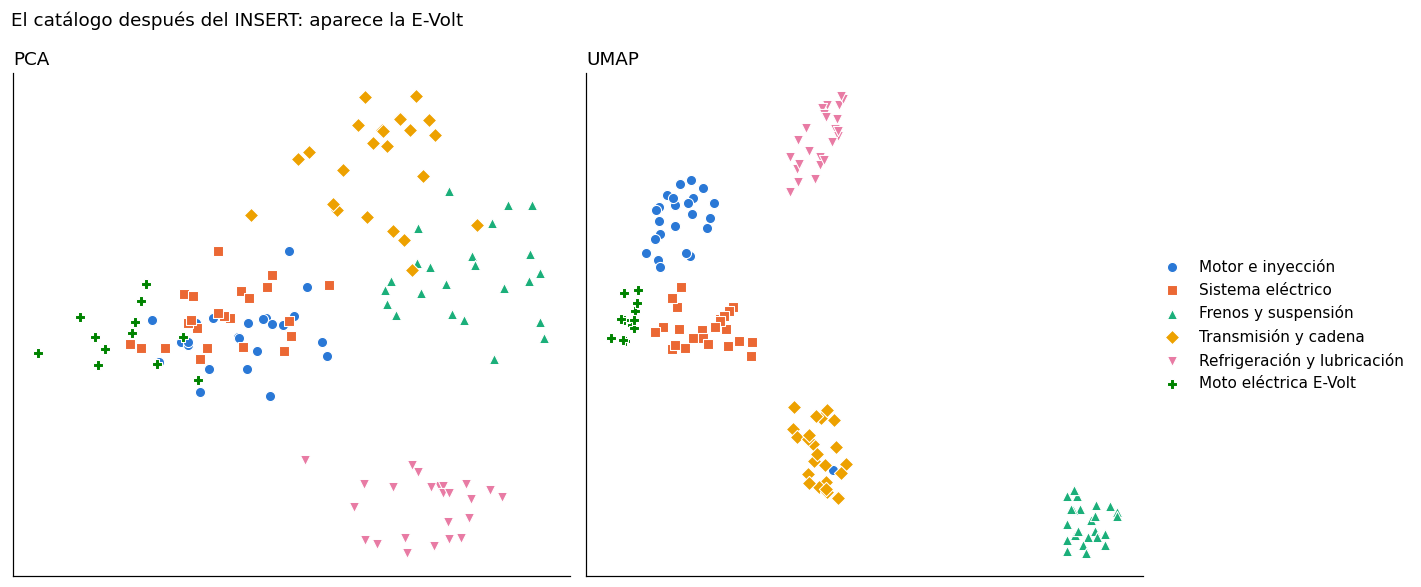

In [ ]:
dibujar_mapa(catalogo, E_catalogo, "El catálogo después del INSERT: aparece la E-Volt")